<a href="https://colab.research.google.com/github/mhasiburrahman/JobShield-AI/blob/main/fake_job_detection_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# Fake Job Advertisement Detection using XAI
# Stage 1: Environment Setup
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("Environment setup completed.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment setup completed.
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving processed_labeled_dataset_without_encoding.xlsx to processed_labeled_dataset_without_encoding.xlsx


In [ ]:
file_name = "processed_labeled_dataset_without_encoding.xlsx"

df = pd.read_excel(file_name)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (54391, 10)


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Number of rows: 54391
Number of columns: 10

Column names:
['job_title', 'location', 'industry', 'salary_range', 'company_profile', 'job_desc', 'skills_desc', 'employment_type', 'fraudulent', 'text']

First 5 records:


,job_title,location,industry,salary_range,company_profile,job_desc,skills_desc,employment_type,fraudulent,text
0,mental health nurse,4688,649,55016-100476,rivera and sons established 2022,arm drive court sure vote earn 5000week immediate hiring contact now at david27gmailcom,basic knowledge in live no degree required flexible hours,Internship,1.0,mental health nurse rivera and sons established 2022 arm drive court sure vote earn 5000week immediate hiring contact now at david27gmailcom basi...
1,conference centre manager,1524,512,53438-93138,davidson jones and gomez established 2003,government whom its bed go tax tree black earn 5000week immediate hiring contact now at justinturnergmailcom,basic knowledge in seek no degree required flexible hours,Part-Time,1.0,conference centre manager davidson jones and gomez established 2003 government whom its bed go tax tree black earn 5000week immediate hiring cont...
2,engineer land,1520,649,45584-105229,allen ltd established 1998,i member discuss follow way there nation earn 5000week immediate hiring contact now at lmackdunnvazquezbiz,basic knowledge in worker no degree required flexible hours,Part-Time,1.0,engineer land allen ltd established 1998 i member discuss follow way there nation earn 5000week immediate hiring contact now at lmackdunnvazquezb...
3,forestwoodland manager,1899,435,66188-139621,forbes ltd established 1990,house across wait approach face earn 5000week immediate hiring contact now at reyesmelaniefostertaylorbiz,basic knowledge in example no degree required flexible hours,Full-Time,1.0,forestwoodland manager forbes ltd established 1990 house across wait approach face earn 5000week immediate hiring contact now at reyesmelaniefost...
4,production designer theatretelevisionfilm,431,1078,32183-115012,jennings martin and sanchez established 1975,case best environmental full finally leader me earn 5000week immediate hiring contact now at matthew83yahoocom,basic knowledge in smile no degree required flexible hours,Temporary,1.0,production designer theatretelevisionfilm jennings martin and sanchez established 1975 case best environmental full finally leader me earn 5000we...


In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
missing = df.isnull().sum().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Missing Values": missing,
        "Percentage (%)": (missing / len(df) * 100).round(2)
    })
)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54391 entries, 0 to 54390
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   job_title        54389 non-null  object 
 1   location         54391 non-null  int64  
 2   industry         54391 non-null  int64  
 3   salary_range     17123 non-null  object 
 4   company_profile  45992 non-null  object 
 5   job_desc         50871 non-null  object 
 6   skills_desc      41522 non-null  object 
 7   employment_type  38823 non-null  object 
 8   fraudulent       44045 non-null  float64
 9   text             54391 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 4.1+ MB

Missing values:


,Missing Values,Percentage (%)
salary_range,37268,68.52
employment_type,15568,28.62
skills_desc,12869,23.66
fraudulent,10346,19.02
company_profile,8399,15.44
job_desc,3520,6.47
job_title,2,0.00
location,0,0.00
industry,0,0.00
text,0,0.00


In [ ]:
print("Unique target values:")
print(df["fraudulent"].unique())

print("\nTarget distribution including missing values:")
print(df["fraudulent"].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    df["fraudulent"]
      .value_counts(dropna=False, normalize=True)
      .mul(100)
      .round(2)
)

Unique target values:
[ 1.  0. nan]

Target distribution including missing values:
fraudulent
0.0    31522
1.0    12523
NaN    10346
Name: count, dtype: int64

Target percentages:
fraudulent
0.0    57.95
1.0    23.02
NaN    19.02
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# Separate labelled and unlabelled records
# ==========================================

df_labelled = df[df["fraudulent"].notna()].copy()
df_missing_label = df[df["fraudulent"].isna()].copy()

# Convert target to integer
df_labelled["fraudulent"] = df_labelled["fraudulent"].astype(int)

print("Original dataset:", df.shape)
print("Labelled records:", df_labelled.shape)
print("Records with missing target:", df_missing_label.shape)

print("\nLabelled target distribution:")
print(df_labelled["fraudulent"].value_counts())

print("\nLabelled target percentages:")
print(
    df_labelled["fraudulent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Original dataset: (54391, 10)
Labelled records: (44045, 10)
Records with missing target: (10346, 10)

Labelled target distribution:
fraudulent
0    31522
1    12523
Name: count, dtype: int64

Labelled target percentages:
fraudulent
0    71.57
1    28.43
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# Duplicate analysis
# ==========================================

print("Exact duplicate rows:",
      df_labelled.duplicated().sum())

print("Duplicate text entries:",
      df_labelled["text"].duplicated().sum())

print("Duplicate job descriptions:",
      df_labelled["job_desc"].duplicated().sum())

# Check whether the same text appears with conflicting labels
label_counts_per_text = (
    df_labelled.groupby("text")["fraudulent"].nunique()
)

conflicting_texts = (label_counts_per_text > 1).sum()

print("\nTexts associated with both labels:",
      conflicting_texts)

Exact duplicate rows: 2828
Duplicate text entries: 17848
Duplicate job descriptions: 19127

Texts associated with both labels: 0


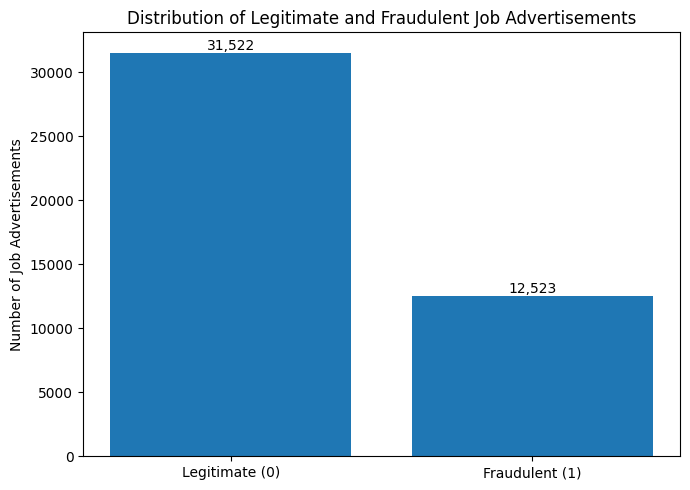

In [ ]:
# ==========================================
# Class distribution
# ==========================================

class_counts = (
    df_labelled["fraudulent"]
    .value_counts()
    .sort_index()
)

labels = ["Legitimate (0)", "Fraudulent (1)"]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, class_counts.values)

plt.title("Distribution of Legitimate and Fraudulent Job Advertisements")
plt.ylabel("Number of Job Advertisements")

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
#  Inspect Duplicate Text Frequency
# ==========================================

text_frequency = (
    df_labelled["text"]
    .value_counts(dropna=False)
    .reset_index()
)

text_frequency.columns = ["text", "frequency"]

print("Top 20 most frequently repeated text entries:")
display(text_frequency.head(20))

print("\nMaximum repetitions of a single text:",
      text_frequency["frequency"].max())

print("Texts appearing more than once:",
      (text_frequency["frequency"] > 1).sum())

print("Texts appearing 5 or more times:",
      (text_frequency["frequency"] >= 5).sum())

print("Texts appearing 10 or more times:",
      (text_frequency["frequency"] >= 10).sum())

Top 20 most frequently repeated text entries:


,text,frequency
0,english teacher abroad we help teachers get safe amp secure jobs abroad play with kids get paid for itã love travel jobs in asia1500 usd monthly 2...,374
1,graduates english teacher abroad conversational we help teachers get safe amp secure jobs abroad play with kids get paid for itã love travel jobs ...,92
2,graduates english teacher abroad conversational we help teachers get safe amp secure jobs abroad play with kids get paid for it love travel jobs i...,64
3,home based payroll typistdata entry clerks positions available we have several openings available in this area earning 100000250000 per weekã we ...,63
4,entry level sales general summary achieves maximum sales profitability growth and account penetration within an assigned territory andor market s...,51
5,english teacher abroad conversational we help teachers get safe amp secure jobs abroad play with kids get paid for itvacancies in asia1500 usd mo...,48
6,graduates english teacher abroad conversational we help teachers get safe amp secure jobs abroad play with kids get paid for it love travel openin...,48
7,data entry adminclerical positions work from home accepting online applications onlyclick here to applyã this is a full time temporary position ...,42
8,graduates english teacher abroad we help teachers get safe amp secure jobs abroad play with kids get paid for it love travel jobs in asia1500 usd ...,40
9,cruise staff wanted urgent 6 ultra luxury american cruise company is urgently looking for the following positionshospitalityã for the many bars ...,40



Maximum repetitions of a single text: 374
Texts appearing more than once: 11420
Texts appearing 5 or more times: 301
Texts appearing 10 or more times: 65


In [ ]:
# ==========================================
# Duplicate Analysis by Class
# ==========================================

for label, name in [(0, "Legitimate"), (1, "Fraudulent")]:

    subset = df_labelled[df_labelled["fraudulent"] == label]

    print(f"\n{name} advertisements")
    print("-" * 35)
    print("Total rows:", len(subset))
    print("Duplicate text entries:",
          subset["text"].duplicated().sum())

    unique_texts = subset["text"].nunique(dropna=False)

    print("Unique text entries:", unique_texts)
    print(
        "Unique-text percentage:",
        round(unique_texts / len(subset) * 100, 2),
        "%"
    )


Legitimate advertisements
-----------------------------------
Total rows: 31522
Duplicate text entries: 16110
Unique text entries: 15412
Unique-text percentage: 48.89 %

Fraudulent advertisements
-----------------------------------
Total rows: 12523
Duplicate text entries: 1738
Unique text entries: 10785
Unique-text percentage: 86.12 %


In [ ]:
# ==========================================
# Remove Duplicate Text Records
# ==========================================

df_clean = (
    df_labelled
    .drop_duplicates(subset=["text"], keep="first")
    .copy()
    .reset_index(drop=True)
)

print("Before deduplication:", len(df_labelled))
print("After deduplication:", len(df_clean))
print("Records removed:", len(df_labelled) - len(df_clean))

print("\nClass distribution after deduplication:")
print(df_clean["fraudulent"].value_counts())

print("\nClass percentages after deduplication:")
print(
    df_clean["fraudulent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Before deduplication: 44045
After deduplication: 26197
Records removed: 17848

Class distribution after deduplication:
fraudulent
0    15412
1    10785
Name: count, dtype: int64

Class percentages after deduplication:
fraudulent
0    58.83
1    41.17
Name: proportion, dtype: float64


In [ ]:
# ==========================================
#  Missing Value Analysis
# ==========================================

missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

missing_summary = (
    missing_summary
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary)

,Missing_Count,Missing_Percentage
salary_range,13312,50.81
employment_type,3185,12.16
company_profile,3095,11.81
skills_desc,2252,8.60
location,0,0.00
job_title,0,0.00
job_desc,1,0.00
industry,0,0.00
fraudulent,0,0.00
text,0,0.00


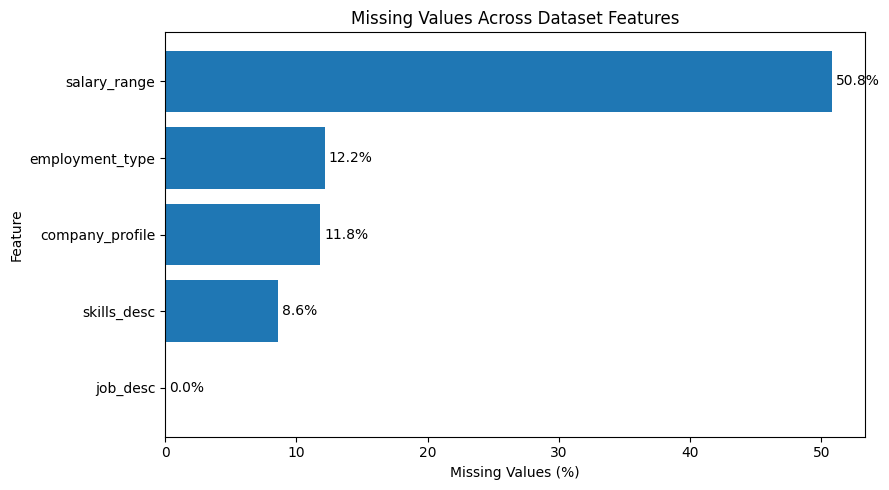

In [ ]:
# Only plot columns containing missing values
missing_plot = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage")

plt.figure(figsize=(9, 5))

bars = plt.barh(
    missing_plot.index,
    missing_plot["Missing_Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing Values Across Dataset Features")

for bar, value in zip(bars, missing_plot["Missing_Percentage"]):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height()/2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
df_clean["text_length"] = (
    df_clean["text"]
    .fillna("")
    .astype(str)
    .str.len()
)

df_clean["word_count"] = (
    df_clean["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Overall text statistics:")
display(
    df_clean[["text_length", "word_count"]]
    .describe()
    .round(2)
)

print("\nText statistics by class:")
display(
    df_clean.groupby("fraudulent")[
        ["text_length", "word_count"]
    ].agg(["mean", "median", "std"]).round(2)
)

Overall text statistics:


,text_length,word_count
count,26197.00,26197.00
mean,1627.69,236.71
std,1538.51,255.65
min,17.00,2.00
25%,223.00,30.00
50%,1352.00,194.00
75%,2623.00,377.00
max,20542.00,9445.00



Text statistics by class:


text_length                  word_count               
                  mean  median      std       mean median     std
fraudulent                                                       
0              2532.56  2374.0  1343.00     370.44  340.0  251.29
1               334.61   218.0   574.44      45.60   29.0   80.28

In [ ]:
print("Empty text:",
      (df_clean["text"].fillna("").str.strip() == "").sum())

print("Texts under 10 words:",
      (df_clean["word_count"] < 10).sum())

print("Texts under 20 words:",
      (df_clean["word_count"] < 20).sum())

print("Texts over 1000 words:",
      (df_clean["word_count"] > 1000).sum())

Empty text: 0
Texts under 10 words: 11
Texts under 20 words: 44
Texts over 1000 words: 152


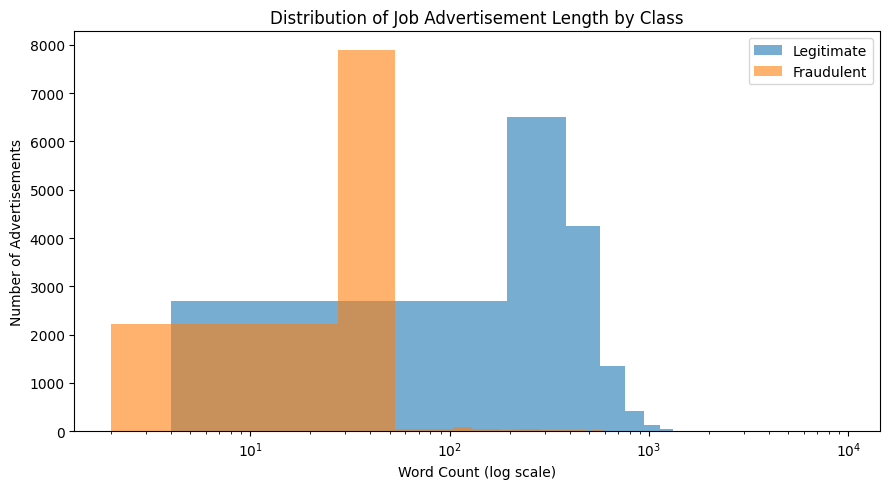

In [ ]:
# ==========================================
# Text Length Distribution by Class
# ==========================================

legitimate_words = df_clean.loc[
    df_clean["fraudulent"] == 0, "word_count"
]

fraudulent_words = df_clean.loc[
    df_clean["fraudulent"] == 1, "word_count"
]

plt.figure(figsize=(9, 5))

plt.hist(
    legitimate_words,
    bins=50,
    alpha=0.6,
    label="Legitimate"
)

plt.hist(
    fraudulent_words,
    bins=50,
    alpha=0.6,
    label="Fraudulent"
)

plt.xscale("log")

plt.xlabel("Word Count (log scale)")
plt.ylabel("Number of Advertisements")
plt.title("Distribution of Job Advertisement Length by Class")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Inspect Example Advertisements
# ==========================================

print("LEGITIMATE EXAMPLES")
print("=" * 80)

for text in df_clean.loc[
    df_clean["fraudulent"] == 0, "text"
].sample(5, random_state=42):

    print(text[:800])
    print("\n" + "-" * 80)


print("\nFRAUDULENT EXAMPLES")
print("=" * 80)

for text in df_clean.loc[
    df_clean["fraudulent"] == 1, "text"
].sample(5, random_state=42):

    print(text[:800])
    print("\n" + "-" * 80)

LEGITIMATE EXAMPLES
network systems engineer ipcortex is a rapidly expanding innovator applying open internet technologies like sip xmpp and webrtc to provide mainstream business communication solutionswe work in informal and very effective teams which provide a perfect environment for talented and focussed individuals to achieve their potential our organic growth ethos presents unlimited opportunities for our outstanding staff to progress as they contribute to our success we are looking for enthusiastic engineers to join our growing technical team large amounts of commercial experience is not a requirement but engineers with a genuine passion for technology and a desire to gain experience in a varied and interesting environment will thrive in our environmwentthis core role is as a member of a team managing o

--------------------------------------------------------------------------------
freelance customer service agent for italian mf babbel enables anyone to learn languages in an ea

In [ ]:
# ==========================================
# Inspect Text Length Extremes
# ==========================================

shortest = df_clean.nsmallest(
    10, "word_count"
)[["fraudulent", "word_count", "text"]]

longest = df_clean.nlargest(
    10, "word_count"
)[["fraudulent", "word_count", "text"]]

print("Shortest advertisements:")
display(shortest)

print("\nLongest advertisements:")
display(longest)

Shortest advertisements:


,fraudulent,word_count,text
25794,1,2,office manager
20249,1,4,real services see rohan
26083,0,4,branch manager name name
23088,1,5,northwestern hospital build a website
10163,1,6,sales executive sales executive sales executive
11323,0,7,software engineer ui engineeringmachine learningweb engineeringsystems engineering
20213,1,7,migration center work with rohan to develop
25990,1,8,customer service rep customer service reps needed asapã
16988,1,9,ux desgin best ux job in the world axureillustrator
25964,1,9,boys girls club rohan will fill in these projects



Longest advertisements:


,fraudulent,word_count,text
22161,0,9445,patient advocate position objectiveã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
23031,0,8329,cardiovascular technologist descriptionã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
21979,0,7962,specimen preparationcollection tech job descriptionã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
21659,0,6034,entry level drafting position responsibilities would include but are not limited to the followingã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
20531,0,5713,chemical dependency counselor job responsibilitiesã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã...
22625,0,5353,data analysis associate job description summaryessential dutiesã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
24778,0,4861,patient service coordinator job summaryã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
22408,0,4602,training administrator key responsibilitiesã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ...
19078,0,4095,medication order clerk job descriptionã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã...
21630,0,3768,buildings reviewerinspector dutiesã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã ã...


In [ ]:
# ==========================================
# Encoding Artefact Analysis
# ==========================================

artefact_pattern = r"[ãâ€ž€™œž]"

df_clean["has_encoding_artefact"] = (
    df_clean["text"]
    .fillna("")
    .astype(str)
    .str.contains(artefact_pattern, regex=True, case=False)
)

print(
    "Advertisements containing suspected encoding artefacts:",
    df_clean["has_encoding_artefact"].sum()
)

print(
    "Percentage of dataset:",
    round(df_clean["has_encoding_artefact"].mean() * 100, 2),
    "%"
)

print("\nBy class:")
print(
    pd.crosstab(
        df_clean["fraudulent"],
        df_clean["has_encoding_artefact"],
        margins=True
    )
)

Advertisements containing suspected encoding artefacts: 14829
Percentage of dataset: 56.61 %

By class:
has_encoding_artefact  False   True    All
fraudulent                                
0                       1130  14282  15412
1                      10238    547  10785
All                    11368  14829  26197


In [ ]:
# ==========================================
# Inspect Encoding Artefacts
# ==========================================

artefact_examples = df_clean.loc[
    df_clean["has_encoding_artefact"],
    ["fraudulent", "word_count", "text"]
].head(20)

display(artefact_examples)

,fraudulent,word_count,text
10001,0,663,customer service cloud video production 90 seconds the worlds cloud video production service90 seconds is the worlds cloud video production servi...
10002,0,359,commissioning machinery assistant cma valor services provides workforce solutions that meet the needs of companies across the private sector with ...
10003,0,611,account executive washington dc our passion for improving quality of life through geography is at the heart of everything we doã esriãââs geograp...
10004,0,535,bill review manager spotsource solutions llc is a global human capital management consulting firm headquartered in miami florida founded in januar...
10005,0,482,accounting clerk job overviewapex is an environmental consulting firm that offers stable leadership and growth and views employees as valuable re...
10006,0,427,head of content mf founded in 2009 theã fonpit agã rose with its international web portalã androidpitã to the worlds largest android community eve...
10007,0,597,lead guest service specialist airenvyãââs mission is to provide lucrative yet hassle free full service short term property management all around t...
10008,0,246,hp bsm sme solutions3 is a womanowned small business whose focus is it service management using best of breed technology and implementing industry...
10009,0,334,customer service associate part time novitex enterprise solutions formerly pitney bowes management services delivers innovative document and comm...
10010,0,634,aspnet developer job opportunity at united statesnew jersey position url_86fd830a95a64e2b30ceed829e63fd384c289e4f01e3c93608b42a84f6e662dd develo...


In [ ]:
features_to_check = [
    "salary_range",
    "employment_type",
    "company_profile",
    "skills_desc",
    "job_desc"
]

results = []

for col in features_to_check:

    missing_group = df_clean[df_clean[col].isna()]
    present_group = df_clean[df_clean[col].notna()]

    results.append({
        "Feature": col,
        "Missing_Count": len(missing_group),
        "Fraud_Rate_When_Missing (%)":
            round(missing_group["fraudulent"].mean() * 100, 2),
        "Fraud_Rate_When_Present (%)":
            round(present_group["fraudulent"].mean() * 100, 2)
    })

missing_fraud_analysis = pd.DataFrame(results)

display(missing_fraud_analysis)

,Feature,Missing_Count,Fraud_Rate_When_Missing (%),Fraud_Rate_When_Present (%)
0,salary_range,13312,3.94,79.63
1,employment_type,3185,5.18,46.15
2,company_profile,3095,15.12,44.66
3,skills_desc,2252,5.60,44.51
4,job_desc,1,100.00,41.17


In [ ]:
# ==========================================
# Encoding Artefact Analysis
# ==========================================

artefact_pattern = r"[ãâ€ž€™œž]"

df_clean["has_encoding_artefact"] = (
    df_clean["text"]
    .fillna("")
    .astype(str)
    .str.contains(artefact_pattern, regex=True, case=False)
)

print(
    "Advertisements containing suspected encoding artefacts:",
    df_clean["has_encoding_artefact"].sum()
)

print(
    "Percentage of dataset:",
    round(df_clean["has_encoding_artefact"].mean() * 100, 2),
    "%"
)

print("\nBy class:")
print(
    pd.crosstab(
        df_clean["fraudulent"],
        df_clean["has_encoding_artefact"],
        margins=True
    )
)

Advertisements containing suspected encoding artefacts: 14829
Percentage of dataset: 56.61 %

By class:
has_encoding_artefact  False   True    All
fraudulent                                
0                       1130  14282  15412
1                      10238    547  10785
All                    11368  14829  26197


In [ ]:
# ==========================================
# Inspect Encoding Artefact Examples
# ==========================================

artefact_examples = df_clean.loc[
    df_clean["has_encoding_artefact"],
    ["fraudulent", "word_count", "text"]
].head(20)

display(artefact_examples)

,fraudulent,word_count,text
10001,0,663,customer service cloud video production 90 seconds the worlds cloud video production service90 seconds is the worlds cloud video production servi...
10002,0,359,commissioning machinery assistant cma valor services provides workforce solutions that meet the needs of companies across the private sector with ...
10003,0,611,account executive washington dc our passion for improving quality of life through geography is at the heart of everything we doã esriãââs geograp...
10004,0,535,bill review manager spotsource solutions llc is a global human capital management consulting firm headquartered in miami florida founded in januar...
10005,0,482,accounting clerk job overviewapex is an environmental consulting firm that offers stable leadership and growth and views employees as valuable re...
10006,0,427,head of content mf founded in 2009 theã fonpit agã rose with its international web portalã androidpitã to the worlds largest android community eve...
10007,0,597,lead guest service specialist airenvyãââs mission is to provide lucrative yet hassle free full service short term property management all around t...
10008,0,246,hp bsm sme solutions3 is a womanowned small business whose focus is it service management using best of breed technology and implementing industry...
10009,0,334,customer service associate part time novitex enterprise solutions formerly pitney bowes management services delivers innovative document and comm...
10010,0,634,aspnet developer job opportunity at united statesnew jersey position url_86fd830a95a64e2b30ceed829e63fd384c289e4f01e3c93608b42a84f6e662dd develo...


In [ ]:
# ==========================================
# Text Cleaning
# ==========================================

import re
import unicodedata

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Normalise Unicode characters
    text = unicodedata.normalize("NFKD", text)

    # Remove common encoding artefact characters
    text = re.sub(r"[ãâ€ž€™œž]+", " ", text, flags=re.IGNORECASE)

    # Remove non-ASCII characters left by corrupted encoding
    text = text.encode("ascii", errors="ignore").decode()

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove excessive punctuation/special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalise whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


df_clean["clean_text"] = df_clean["text"].apply(clean_text)

print("Text cleaning completed.")

print("\nOriginal:")
print(df_clean["text"].iloc[0][:500])

print("\nCleaned:")
print(df_clean["clean_text"].iloc[0][:500])

Text cleaning completed.

Original:
mental health nurse rivera and sons  established 2022 arm drive court sure vote earn 5000week immediate hiring contact now at david27gmailcom basic knowledge in live no degree required flexible hours

Cleaned:
mental health nurse rivera and sons established 2022 arm drive court sure vote earn 5000week immediate hiring contact now at david27gmailcom basic knowledge in live no degree required flexible hours


In [ ]:
# ==========================================
# Validate Cleaned Text
# ==========================================

df_clean["clean_word_count"] = (
    df_clean["clean_text"]
    .str.split()
    .str.len()
)

print("Empty cleaned texts:",
      (df_clean["clean_text"] == "").sum())

print("Cleaned texts under 10 words:",
      (df_clean["clean_word_count"] < 10).sum())

print("Average cleaned word count:",
      round(df_clean["clean_word_count"].mean(), 2))

print("\nCleaned word count by class:")

display(
    df_clean.groupby("fraudulent")["clean_word_count"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

Empty cleaned texts: 0
Cleaned texts under 10 words: 11
Average cleaned word count: 237.07

Cleaned word count by class:


,mean,median,std,min,max
fraudulent,,,,,
0,371.01,340.0,251.37,4,9445
1,45.66,29.0,80.48,2,1285


In [ ]:
# ==========================================
# Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split

X = df_clean["clean_text"]
y = df_clean["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training samples: 20957
Testing samples: 5240

Training class distribution:
fraudulent
0    0.5883
1    0.4117
Name: proportion, dtype: float64

Testing class distribution:
fraudulent
0    0.5884
1    0.4116
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# TF-IDF Feature Extraction
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

# Transform only - do not fit again
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (20957, 10000)
Testing TF-IDF shape: (5240, 10000)
Vocabulary size: 10000


In [ ]:
# ==========================================
# Logistic Regression Baseline
# ==========================================

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [ ]:
# ==========================================
# Logistic Regression Evaluation
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

y_pred_lr = lr_model.predict(X_test_tfidf)
y_prob_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
pr_auc_lr = average_precision_score(y_test, y_prob_lr)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)

print(f"Accuracy : {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall   : {recall_lr:.4f}")
print(f"F1-score : {f1_lr:.4f}")
print(f"ROC-AUC  : {roc_auc_lr:.4f}")
print(f"PR-AUC   : {pr_auc_lr:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Legitimate", "Fraudulent"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
Accuracy : 0.9803
Precision: 0.9995
Recall   : 0.9527
F1-score : 0.9756
ROC-AUC  : 0.9978
PR-AUC   : 0.9976

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      1.00      0.98      3083
  Fraudulent       1.00      0.95      0.98      2157

    accuracy                           0.98      5240
   macro avg       0.98      0.98      0.98      5240
weighted avg       0.98      0.98      0.98      5240

Confusion Matrix:
[[3082    1]
 [ 102 2055]]


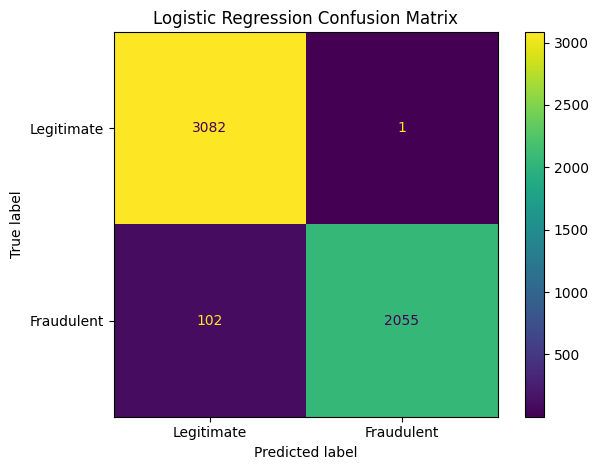

In [ ]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["Legitimate", "Fraudulent"],
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Random Forest Model
# ==========================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
# ==========================================
# Random Forest Evaluation
# ==========================================

y_pred_rf = rf_model.predict(X_test_tfidf)
y_prob_rf = rf_model.predict_proba(X_test_tfidf)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("RANDOM FOREST RESULTS")
print("=" * 40)

print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")
print(f"PR-AUC   : {pr_auc_rf:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Legitimate", "Fraudulent"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST RESULTS
Accuracy : 0.9857
Precision: 1.0000
Recall   : 0.9652
F1-score : 0.9823
ROC-AUC  : 0.9980
PR-AUC   : 0.9978

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.98      1.00      0.99      3083
  Fraudulent       1.00      0.97      0.98      2157

    accuracy                           0.99      5240
   macro avg       0.99      0.98      0.99      5240
weighted avg       0.99      0.99      0.99      5240

Confusion Matrix:
[[3083    0]
 [  75 2082]]


In [ ]:
# ==========================================
# XGBoost Model
# ==========================================

from xgboost import XGBClassifier

# Calculate class weighting from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale pos weight:", round(scale_pos_weight, 3))

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_tfidf, y_train)

print("XGBoost training completed.")

Scale pos weight: 1.429
XGBoost training completed.


In [ ]:
# ==========================================
# XGBoost Evaluation
# ==========================================

y_pred_xgb = xgb_model.predict(X_test_tfidf)
y_prob_xgb = xgb_model.predict_proba(X_test_tfidf)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)

print("XGBOOST RESULTS")
print("=" * 40)

print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-score : {f1_xgb:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb:.4f}")
print(f"PR-AUC   : {pr_auc_xgb:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Legitimate", "Fraudulent"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBOOST RESULTS
Accuracy : 0.9872
Precision: 0.9971
Recall   : 0.9717
F1-score : 0.9843
ROC-AUC  : 0.9986
PR-AUC   : 0.9985

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.98      1.00      0.99      3083
  Fraudulent       1.00      0.97      0.98      2157

    accuracy                           0.99      5240
   macro avg       0.99      0.98      0.99      5240
weighted avg       0.99      0.99      0.99      5240

Confusion Matrix:
[[3077    6]
 [  61 2096]]


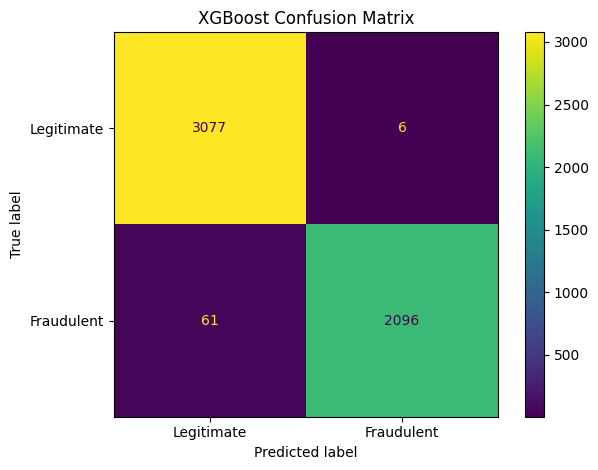

In [ ]:
# ==========================================
# XGBoost Confusion Matrix
# ==========================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["Legitimate", "Fraudulent"],
    values_format="d"
)

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Model Performance Comparison
# ==========================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_rf,
        accuracy_xgb
    ],
    "Precision": [
        precision_lr,
        precision_rf,
        precision_xgb
    ],
    "Recall": [
        recall_lr,
        recall_rf,
        recall_xgb
    ],
    "F1-Score": [
        f1_lr,
        f1_rf,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc_lr,
        roc_auc_rf,
        roc_auc_xgb
    ],
    "PR-AUC": [
        pr_auc_lr,
        pr_auc_rf,
        pr_auc_xgb
    ]
})

display(
    model_comparison
    .set_index("Model")
    .round(4)
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.9803,0.9995,0.9527,0.9756,0.9978,0.9976
Random Forest,0.9857,1.0000,0.9652,0.9823,0.9980,0.9978
XGBoost,0.9872,0.9971,0.9717,0.9843,0.9986,0.9985


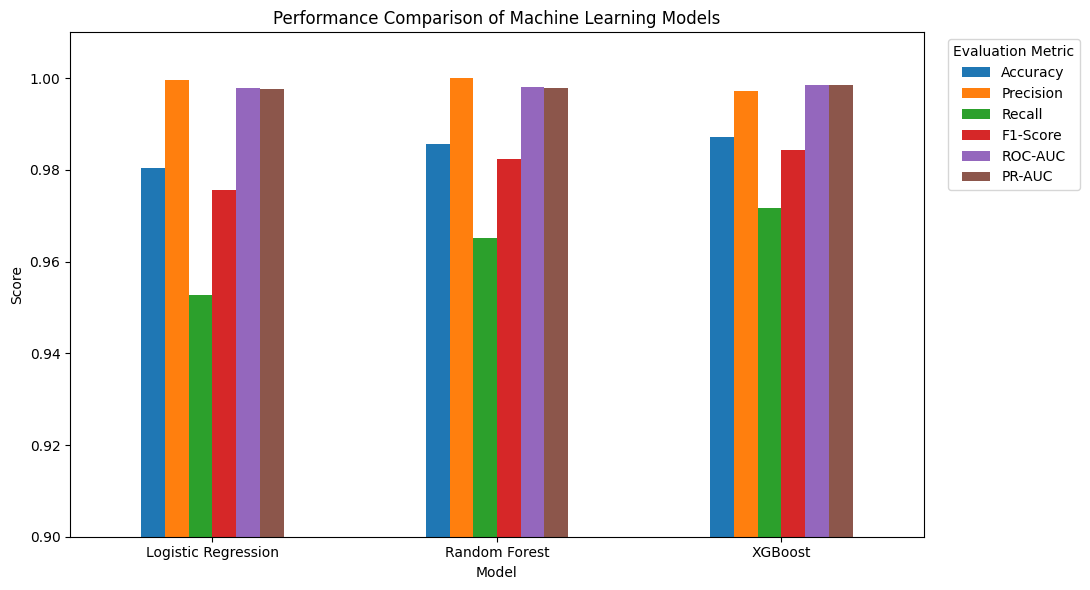

In [ ]:
# ==========================================
# Model Performance Visualisation
# ==========================================

comparison_plot = (
    model_comparison
    .set_index("Model")
)

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")

# Zoom in because all models score highly
plt.ylim(0.90, 1.01)

plt.xticks(rotation=0)
plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Word Count Only Baseline
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

X_length = df_clean[["clean_word_count"]]
y_length = df_clean["fraudulent"]

X_len_train, X_len_test, y_len_train, y_len_test = train_test_split(
    X_length,
    y_length,
    test_size=0.20,
    random_state=42,
    stratify=y_length
)

length_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

length_model.fit(X_len_train, y_len_train)

y_len_pred = length_model.predict(X_len_test)
y_len_prob = length_model.predict_proba(X_len_test)[:, 1]

print("WORD-COUNT-ONLY BASELINE")
print("=" * 40)

print(f"Accuracy : {accuracy_score(y_len_test, y_len_pred):.4f}")
print(f"Precision: {precision_score(y_len_test, y_len_pred):.4f}")
print(f"Recall   : {recall_score(y_len_test, y_len_pred):.4f}")
print(f"F1-score : {f1_score(y_len_test, y_len_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_len_test, y_len_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_len_test, y_len_pred))

WORD-COUNT-ONLY BASELINE
Accuracy : 0.9672
Precision: 0.9906
Recall   : 0.9291
F1-score : 0.9589
ROC-AUC  : 0.9735

Confusion Matrix:
[[3064   19]
 [ 153 2004]]


In [ ]:
# ==========================================
# Most Influential Logistic Regression Terms
# ==========================================

feature_names = np.array(tfidf.get_feature_names_out())
coefficients = lr_model.coef_[0]

top_fraud_indices = np.argsort(coefficients)[-20:][::-1]
top_legitimate_indices = np.argsort(coefficients)[:20]

top_fraud_terms = pd.DataFrame({
    "Term": feature_names[top_fraud_indices],
    "Coefficient": coefficients[top_fraud_indices]
})

top_legitimate_terms = pd.DataFrame({
    "Term": feature_names[top_legitimate_indices],
    "Coefficient": coefficients[top_legitimate_indices]
})

print("Terms most strongly associated with FRAUDULENT advertisements:")
display(top_fraud_terms)

print("\nTerms most strongly associated with LEGITIMATE advertisements:")
display(top_legitimate_terms)

Terms most strongly associated with FRAUDULENT advertisements:


,Term,Coefficient
0,earn,3.280223
1,no,3.046634
2,immediate,2.983788
3,data entry,2.853057
4,contact,2.812419
5,hiring,2.783074
6,no degree,2.769535
7,required flexible,2.759145
8,5000week immediate,2.759145
9,5000week,2.759145



Terms most strongly associated with LEGITIMATE advertisements:


,Term,Coefficient
0,of,-2.607848
1,our,-2.254559
2,an,-1.957071
3,english,-1.666807
4,web,-1.660186
5,is,-1.655322
6,companies,-1.644544
7,growing,-1.575434
8,digital,-1.555303
9,team,-1.512960


In [ ]:
# ==========================================
# Performance by Advertisement Length
# ==========================================

test_results = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "prediction": y_pred_xgb,
    "probability": y_prob_xgb
})

test_results["word_count"] = (
    test_results["text"]
    .str.split()
    .str.len()
)

test_results["length_group"] = pd.cut(
    test_results["word_count"],
    bins=[0, 50, 150, 300, float("inf")],
    labels=[
        "Very Short (≤50)",
        "Short (51–150)",
        "Medium (151–300)",
        "Long (>300)"
    ]
)

length_performance = []

for group in test_results["length_group"].dropna().unique():

    subset = test_results[
        test_results["length_group"] == group
    ]

    length_performance.append({
        "Length Group": group,
        "Samples": len(subset),
        "Fraud Rate (%)":
            subset["true_label"].mean() * 100,
        "Accuracy":
            accuracy_score(
                subset["true_label"],
                subset["prediction"]
            ),
        "Precision":
            precision_score(
                subset["true_label"],
                subset["prediction"],
                zero_division=0
            ),
        "Recall":
            recall_score(
                subset["true_label"],
                subset["prediction"],
                zero_division=0
            ),
        "F1-Score":
            f1_score(
                subset["true_label"],
                subset["prediction"],
                zero_division=0
            )
    })

length_performance = pd.DataFrame(length_performance)

display(
    length_performance
    .sort_values("Length Group")
    .round(4)
)

,Length Group,Samples,Fraud Rate (%),Accuracy,Precision,Recall,F1-Score
2,Long (>300),1902,2.7865,0.9911,0.9737,0.6981,0.8132
3,Medium (151–300),953,4.5121,0.9717,1.0000,0.3721,0.5424
0,Short (51–150),324,12.6543,0.9506,0.8571,0.7317,0.7895
1,Very Short (≤50),2061,98.0107,0.9966,1.0000,0.9965,0.9983


In [ ]:
# ==========================================
# XGBoost Error Analysis
# ==========================================

error_analysis = test_results[
    test_results["true_label"] != test_results["prediction"]
].copy()

false_negatives = error_analysis[
    (error_analysis["true_label"] == 1) &
    (error_analysis["prediction"] == 0)
].sort_values("probability")

false_positives = error_analysis[
    (error_analysis["true_label"] == 0) &
    (error_analysis["prediction"] == 1)
].sort_values("probability", ascending=False)

print("Total classification errors:", len(error_analysis))
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

print("\nFalse-negative word-count statistics:")

display(
    false_negatives["word_count"]
    .describe()
    .round(2)
)

print("\nExamples of missed fraudulent advertisements:")

display(
    false_negatives[
        ["word_count", "probability", "text"]
    ].head(10)
)

Total classification errors: 67
False negatives: 61
False positives: 6

False-negative word-count statistics:


,word_count
count,61.00
mean,261.43
std,207.50
min,5.00
25%,132.00
50%,218.00
75%,332.00
max,993.00



Examples of missed fraudulent advertisements:


,word_count,probability,text
18570,378,0.000078,frontendjavascript engineer workable is a productdriven software company with thousands of enterprise users and millions in venture funding were b...
11289,431,0.003419,big data engineer positiona big data engineerlocation san francisco cadurationa 6 months ctha skillsbihadoopjava mapreducerdbmsjob descriptionseni...
13577,260,0.005457,account sales managers 80130000yr we have aggressive growth plans in place for the coming years we provide a much needed service in facilitating t...
15658,640,0.009561,product insight analyst property and casualty insurance 2168 2168job title product insight analyst property and casualty insurancerole consultantr...
16690,993,0.010989,oilgas technical manager job descriptionsenior manager of maintenance senior technical manager the senior technical manager stm reports to the dir...
25986,220,0.011154,work from home 20hr we are seeking professionals from all walks of life and a variety of professions to work from home ideal candidates are hardwo...
25987,178,0.012513,office clerk we is a market leader in manufacturing and designing high quality led lighting products with a global presence we are a fast growing ...
26011,218,0.013694,webcam model internet modeling is a premier adult modeling agency recruiting and hiring webcam models for high paying webcam jobswe are one of the...
14485,206,0.015429,senior sales professionals do you have the sales skills or entrepreneurial drive to join usflexkom gmbh is a german company experiencing massive s...
15701,366,0.015795,field service tech capital equipment 1970 1970job title field service tech capital equipmentrole technician maintenancerelocation available no mus...


In [ ]:
# ==========================================
# SHAP Setup
# ==========================================

!pip install shap -q

import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
# ==========================================
# Create SHAP Explainer
# ==========================================

explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [ ]:
# ==========================================
# Select SHAP Analysis Sample
# ==========================================

sample_size = min(500, X_test_tfidf.shape[0])

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    X_test_tfidf.shape[0],
    size=sample_size,
    replace=False
)

X_shap = X_test_tfidf[sample_indices]

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (500, 10000)


In [ ]:
# ==========================================
# Calculate SHAP Values
# ==========================================

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated.")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values calculated.
SHAP values shape: (500, 10000)


In [ ]:
# ==========================================
# Global SHAP Feature Importance
# ==========================================

feature_names = np.array(tfidf.get_feature_names_out())

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_ABS_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values("Mean_ABS_SHAP", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 globally important features:")
display(shap_importance.head(20))

Top 20 globally important features:


,Feature,Mean_ABS_SHAP
0,earn,1.694919
1,no,0.775005
2,to,0.523375
3,hours,0.522122
4,of,0.358977
5,immediate,0.304938
6,at,0.292042
7,required,0.285623
8,contact,0.282546
9,knowledge,0.201412


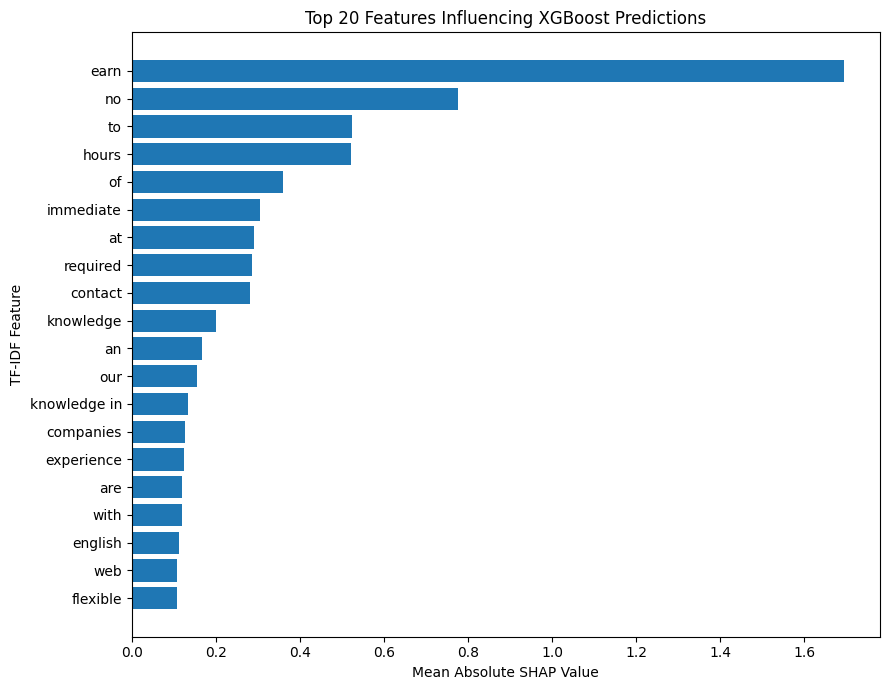

In [ ]:
# ==========================================
# Global SHAP Importance Plot
# ==========================================

top_features = shap_importance.head(20).sort_values(
    "Mean_ABS_SHAP"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["Feature"],
    top_features["Mean_ABS_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("TF-IDF Feature")
plt.title("Top 20 Features Influencing XGBoost Predictions")

plt.tight_layout()
plt.show()

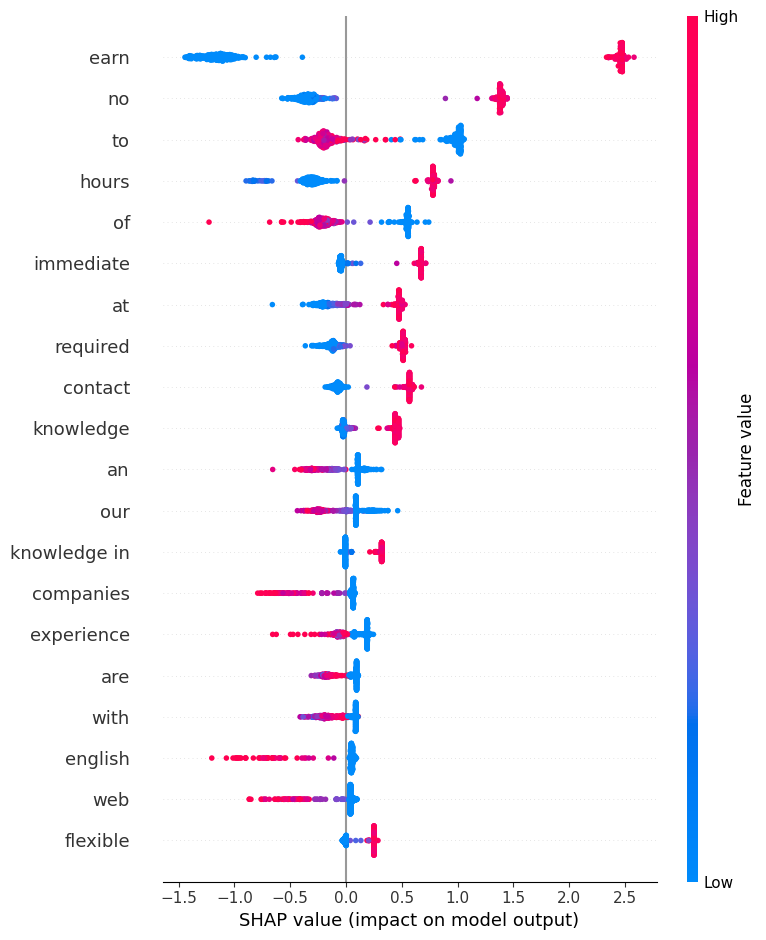

In [ ]:
# ==========================================
# SHAP Summary Plot
# ==========================================

X_shap_dense = X_shap.toarray()

shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    max_display=20,
    show=True
)

In [ ]:
# ==========================================
# Prepare Individual Prediction Explanations
# ==========================================

test_positions = np.arange(len(y_test))

correct_fraud_positions = test_positions[
    (y_test.to_numpy() == 1) &
    (y_pred_xgb == 1)
]

correct_legitimate_positions = test_positions[
    (y_test.to_numpy() == 0) &
    (y_pred_xgb == 0)
]

missed_fraud_positions = test_positions[
    (y_test.to_numpy() == 1) &
    (y_pred_xgb == 0)
]

print("Correct fraudulent predictions:", len(correct_fraud_positions))
print("Correct legitimate predictions:", len(correct_legitimate_positions))
print("Missed fraudulent predictions:", len(missed_fraud_positions))

Correct fraudulent predictions: 2096
Correct legitimate predictions: 3077
Missed fraudulent predictions: 61


In [ ]:
# ==========================================
# Explain an Individual Prediction
# ==========================================

def explain_prediction(position, title):

    row = X_test_tfidf[position]

    prediction = xgb_model.predict(row)[0]
    probability = xgb_model.predict_proba(row)[0, 1]
    actual = y_test.iloc[position]

    row_shap = explainer.shap_values(row)

    explanation = shap.Explanation(
        values=row_shap[0],
        base_values=explainer.expected_value,
        data=row.toarray()[0],
        feature_names=feature_names
    )

    print(title)
    print("=" * 60)
    print("Actual class:",
          "Fraudulent" if actual == 1 else "Legitimate")
    print("Predicted class:",
          "Fraudulent" if prediction == 1 else "Legitimate")
    print(f"Fraud probability: {probability:.4f}")

    print("\nAdvertisement:")
    print(X_test.iloc[position][:1000])

    shap.plots.waterfall(
        explanation,
        max_display=15
    )

Correctly Detected Fraudulent Advertisement
Actual class: Fraudulent
Predicted class: Fraudulent
Fraud probability: 1.0000

Advertisement:
engineer civil consulting leonard turner and shields established 1988 most ahead window sister bar in earn 5000week immediate hiring contact now at dominique63tuckerbrowncom basic knowledge in store no degree required flexible hours


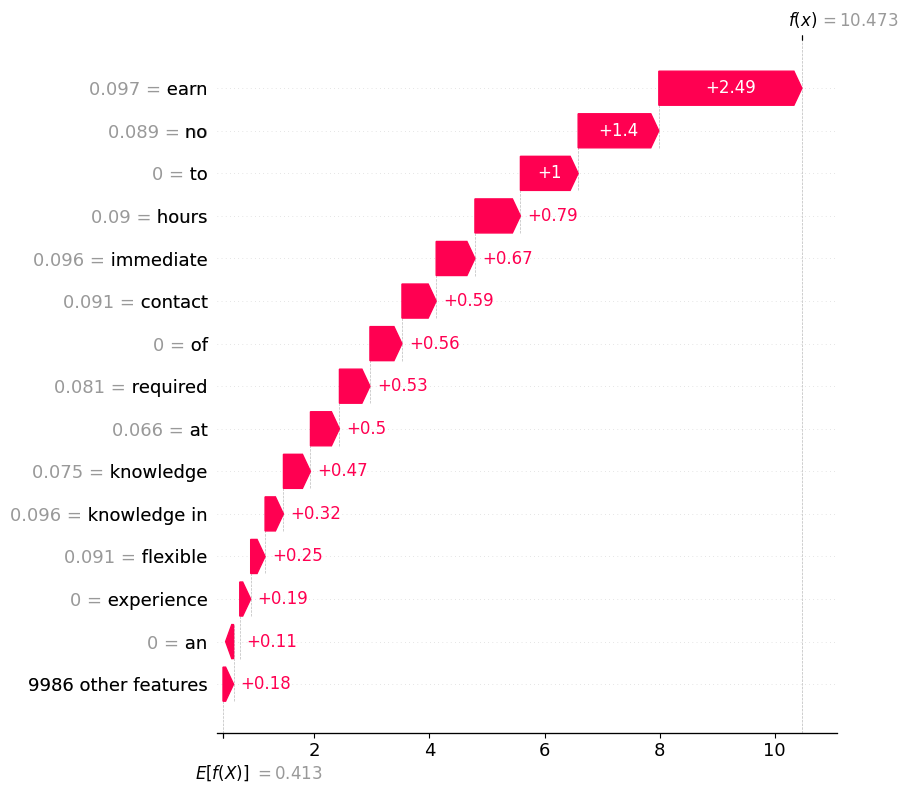

In [ ]:
# ==========================================
# Local SHAP Explanations
# ==========================================

correct_fraud = correct_fraud_positions[0]
correct_legitimate = correct_legitimate_positions[0]

# Select the most confidently missed fraudulent advertisement
missed_fraud = missed_fraud_positions[
    np.argmin(y_prob_xgb[missed_fraud_positions])
]

explain_prediction(
    correct_fraud,
    "Correctly Detected Fraudulent Advertisement"
)

Correctly Identified Legitimate Advertisement
Actual class: Legitimate
Predicted class: Legitimate
Fraud probability: 0.0010

Advertisement:
software and systems developer my group at the nkua noc is looking to hire an individual to work full time on projects related to the it demands of the university and other national and international partners in research and education we are looking to fill the position asap so feel freedom and friendly pressure to forward it to anyone you think should know about this opportunity experience in software development systems administration and operations engineeringserious experience in any one of the three areas is enough if combined with the desire and capacity to learn new stuff quickly


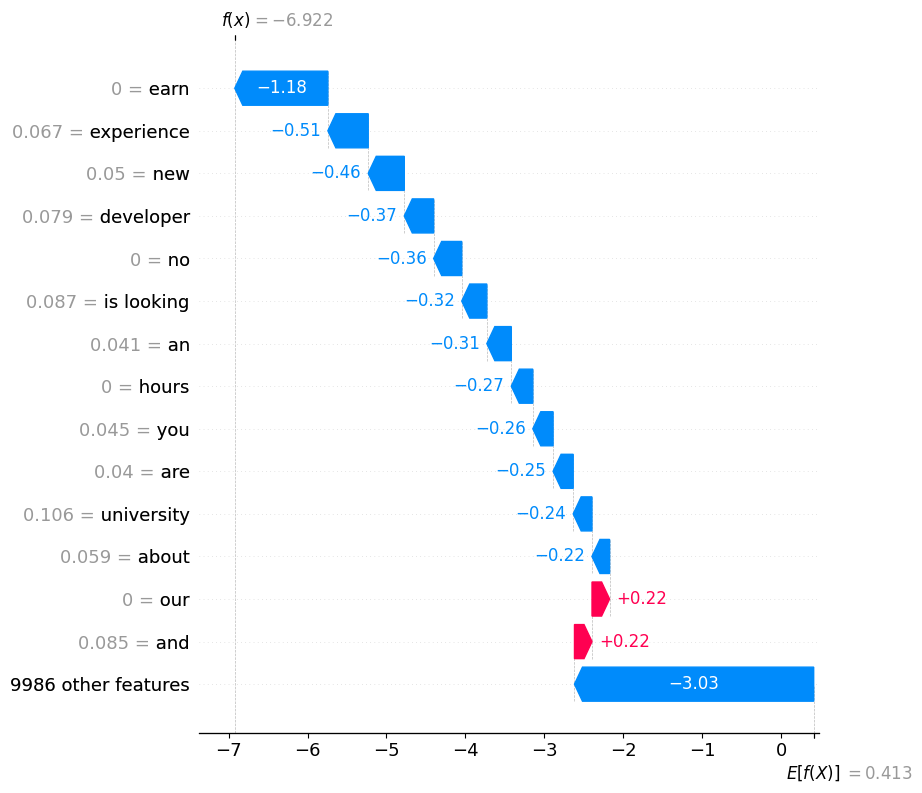

In [ ]:
explain_prediction(
    correct_legitimate,
    "Correctly Identified Legitimate Advertisement"
)

Missed Fraudulent Advertisement
Actual class: Fraudulent
Predicted class: Legitimate
Fraud probability: 0.0001

Advertisement:
frontendjavascript engineer workable is a productdriven software company with thousands of enterprise users and millions in venture funding were building the best recruiting software in the world a frictionless usable robust and highly scalable product that helps companies find and meet great peoplea the quality design and usability of our software is what sets us apart from the competition its good to be an engineer in a company that values good engineering above allwe have a team of remarkably talented and friendly developers a strong engineering culture and a dogged emphasis on customercentric design were working on all sorts of exciting areas of application development web mobile infrastructure performance uiux design integrations with dozens of web services api development modern frontend frameworks scalability video natural language processing data scienc

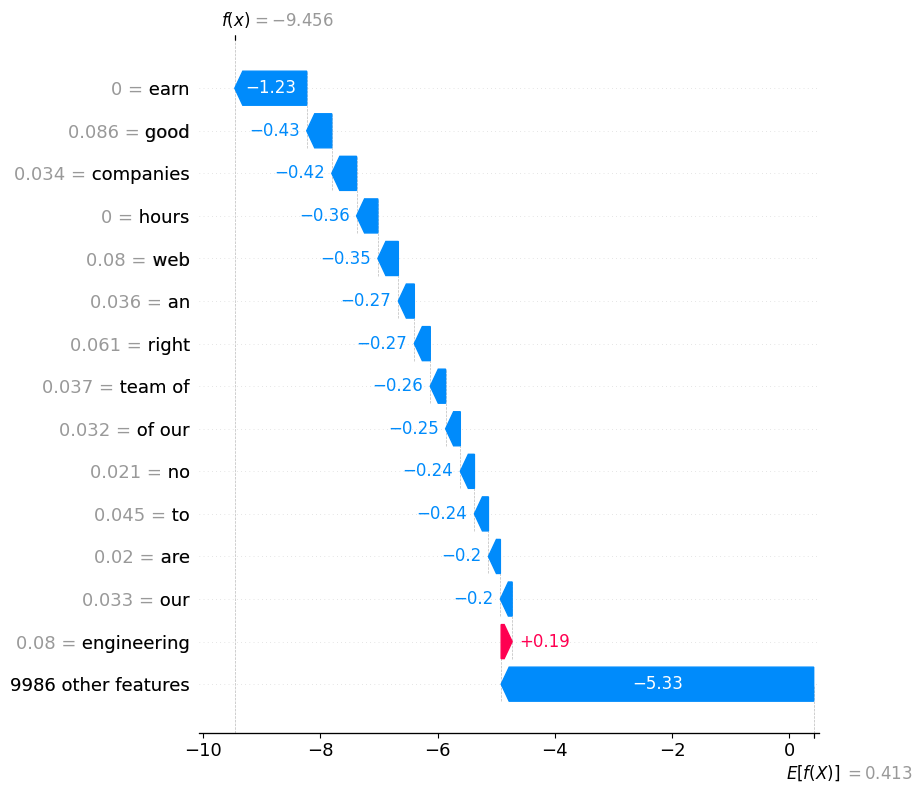

In [ ]:
explain_prediction(
    missed_fraud,
    "Missed Fraudulent Advertisement"
)

In [ ]:
# ==========================================
# TF-IDF with Stop Words Removed
# ==========================================

tfidf_clean = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    stop_words="english"
)

X_train_tfidf_clean = tfidf_clean.fit_transform(X_train)
X_test_tfidf_clean = tfidf_clean.transform(X_test)

print("Training shape:", X_train_tfidf_clean.shape)
print("Testing shape:", X_test_tfidf_clean.shape)
print("Vocabulary size:", len(tfidf_clean.vocabulary_))

Training shape: (20957, 10000)
Testing shape: (5240, 10000)
Vocabulary size: 10000


In [ ]:
# ==========================================
# XGBoost with Refined TF-IDF
# ==========================================

xgb_clean = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_clean.fit(
    X_train_tfidf_clean,
    y_train
)

print("Refined XGBoost training completed.")

Refined XGBoost training completed.


In [ ]:
# ==========================================
# Refined XGBoost Evaluation
# ==========================================

y_pred_xgb_clean = xgb_clean.predict(
    X_test_tfidf_clean
)

y_prob_xgb_clean = xgb_clean.predict_proba(
    X_test_tfidf_clean
)[:, 1]

print("REFINED XGBOOST RESULTS")
print("=" * 40)

print(
    f"Accuracy : "
    f"{accuracy_score(y_test, y_pred_xgb_clean):.4f}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, y_pred_xgb_clean):.4f}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, y_pred_xgb_clean):.4f}"
)

print(
    f"F1-score : "
    f"{f1_score(y_test, y_pred_xgb_clean):.4f}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, y_prob_xgb_clean):.4f}"
)

print(
    f"PR-AUC   : "
    f"{average_precision_score(y_test, y_prob_xgb_clean):.4f}"
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_xgb_clean
    )
)

REFINED XGBOOST RESULTS
Accuracy : 0.9863
Precision: 0.9962
Recall   : 0.9703
F1-score : 0.9831
ROC-AUC  : 0.9984
PR-AUC   : 0.9982

Confusion Matrix:
[[3075    8]
 [  64 2093]]


In [ ]:
# ==========================================
# SHAP Explainer for Refined XGBoost
# ==========================================

feature_names_clean = np.array(
    tfidf_clean.get_feature_names_out()
)

explainer_clean = shap.TreeExplainer(
    xgb_clean
)

sample_size = min(
    500,
    X_test_tfidf_clean.shape[0]
)

rng = np.random.RandomState(42)

sample_indices_clean = rng.choice(
    X_test_tfidf_clean.shape[0],
    size=sample_size,
    replace=False
)

X_shap_clean = X_test_tfidf_clean[
    sample_indices_clean
]

shap_values_clean = explainer_clean.shap_values(
    X_shap_clean
)

print(
    "SHAP values shape:",
    np.array(shap_values_clean).shape
)

SHAP values shape: (500, 10000)


In [ ]:
# ==========================================
# Refined Global SHAP Importance
# ==========================================

mean_abs_shap_clean = (
    np.abs(shap_values_clean)
    .mean(axis=0)
)

shap_importance_clean = pd.DataFrame({
    "Feature": feature_names_clean,
    "Mean_ABS_SHAP": mean_abs_shap_clean
})

shap_importance_clean = (
    shap_importance_clean
    .sort_values(
        "Mean_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_importance_clean.head(20)
)

,Feature,Mean_ABS_SHAP
0,earn,1.579679
1,hours,0.786684
2,immediate,0.759432
3,required,0.500212
4,contact,0.483062
5,experience,0.292009
6,flexible,0.259700
7,hiring,0.240668
8,flexible hours,0.187603
9,degree,0.154253


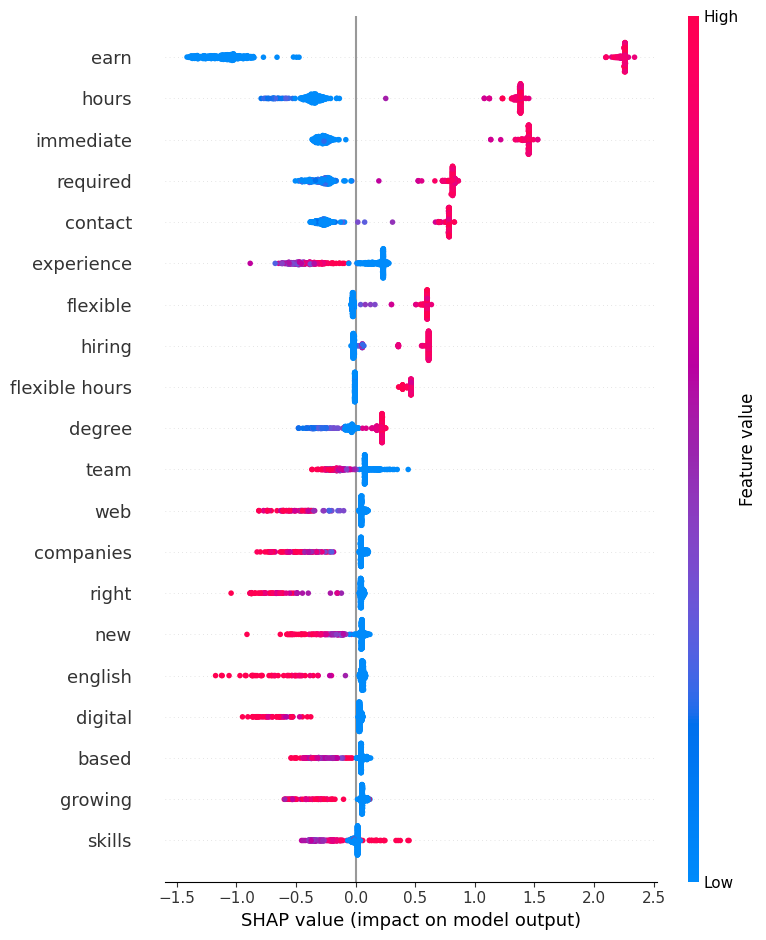

In [ ]:
# ==========================================
# Refined SHAP Summary Plot
# ==========================================

X_shap_clean_dense = (
    X_shap_clean.toarray()
)

shap.summary_plot(
    shap_values_clean,
    X_shap_clean_dense,
    feature_names=feature_names_clean,
    max_display=20,
    show=True
)

In [ ]:
# ==========================================
# JobShield AI Prediction and Explanation
# ==========================================

def jobshield_predict(job_text, top_n=8):

    # Preprocess input
    cleaned_text = clean_text(job_text)

    # TF-IDF transformation
    vector = tfidf_clean.transform([cleaned_text])

    # Prediction
    probability = xgb_clean.predict_proba(vector)[0, 1]
    prediction = int(probability >= 0.30)

    # Risk category
    if probability < 0.30:
        risk_level = "Low"
    elif probability < 0.70:
        risk_level = "Moderate"
    else:
        risk_level = "High"

    # SHAP explanation
    local_shap = explainer_clean.shap_values(vector)[0]
    feature_values = vector.toarray()[0]

    explanation_df = pd.DataFrame({
        "Feature": feature_names_clean,
        "TF_IDF": feature_values,
        "SHAP_Value": local_shap
    })

    # Keep terms actually present in the advertisement
    explanation_df = explanation_df[
        explanation_df["TF_IDF"] > 0
    ].copy()

    explanation_df["Absolute_Impact"] = (
        explanation_df["SHAP_Value"].abs()
    )

    explanation_df = explanation_df.sort_values(
        "Absolute_Impact",
        ascending=False
    )

    top_reasons = explanation_df.head(top_n).copy()

    top_reasons["Effect"] = np.where(
        top_reasons["SHAP_Value"] > 0,
        "Pushes toward Fraudulent",
        "Pushes toward Legitimate"
    )

    # Display prediction
    print("JOBSHIELD AI")
    print("=" * 55)

    print(
        "Prediction:",
        "FRAUDULENT" if prediction == 1 else "LEGITIMATE"
    )

    print(f"Fraud probability: {probability:.2%}")
    print("Risk level:", risk_level)

    print("\nMost influential terms:")

    display(
        top_reasons[
            ["Feature", "SHAP_Value", "Effect"]
        ].reset_index(drop=True)
    )

    # Human-readable explanation
    create_human_explanation(
        top_reasons,
        prediction,
        probability
    )

    return {
        "prediction": prediction,
        "fraud_probability": probability,
        "risk_level": risk_level,
        "explanation": top_reasons
    }

In [ ]:
test_job = """
Immediate hiring. Earn 5000 per week working from home.
No degree required. Flexible hours available.
Contact us now to start immediately.
"""

result = jobshield_predict(test_job)

JOBSHIELD AI
Prediction: FRAUDULENT
Fraud probability: 99.99%
Risk level: High

Most influential terms:


,Feature,SHAP_Value,Effect
0,earn,2.260943,Pushes toward Fraudulent
1,immediate,1.477572,Pushes toward Fraudulent
2,hours,1.235242,Pushes toward Fraudulent
3,required,0.815401,Pushes toward Fraudulent
4,contact,0.723134,Pushes toward Fraudulent
5,hiring,0.612189,Pushes toward Fraudulent
6,flexible,0.521593,Pushes toward Fraudulent
7,flexible hours,0.394361,Pushes toward Fraudulent



EXPLANATION
The model estimated a 99.99% probability that this advertisement is fraudulent.

Terms increasing the fraud score: earn, immediate, hours, required, contact

These terms show factors that influenced the model's prediction. They should not be interpreted as proof that an advertisement is fraudulent or legitimate.


In [ ]:
test_job_2 = """
We are seeking an experienced software engineer to join our
development team. The successful candidate will work with
cross-functional teams to design, develop and maintain software
applications. Applicants should have experience in Python,
software engineering principles and collaborative development.
"""

result = jobshield_predict(test_job_2)

JOBSHIELD AI
Prediction: LEGITIMATE
Fraud probability: 1.96%
Risk level: Low

Most influential terms:


,Feature,SHAP_Value,Effect
0,engineering,0.693820,Pushes toward Fraudulent
1,candidate,-0.491961,Pushes toward Legitimate
2,team,-0.451581,Pushes toward Legitimate
3,maintain,0.236390,Pushes toward Fraudulent
4,experience,-0.184804,Pushes toward Legitimate
5,experienced,-0.154600,Pushes toward Legitimate
6,software,-0.114740,Pushes toward Legitimate
7,work,-0.099387,Pushes toward Legitimate



EXPLANATION
The model estimated a 1.96% probability of fraud and classified the advertisement as legitimate.

Terms increasing the fraud score: engineering, maintain
Terms decreasing the fraud score: candidate, team, experience, experienced, software

These terms show factors that influenced the model's prediction. They should not be interpreted as proof that an advertisement is fraudulent or legitimate.


In [ ]:
# ==========================================
# Human-Readable SHAP Explanation
# ==========================================

def create_human_explanation(top_reasons, prediction, probability):

    fraud_terms = top_reasons[
        top_reasons["SHAP_Value"] > 0
    ]["Feature"].tolist()

    legitimate_terms = top_reasons[
        top_reasons["SHAP_Value"] < 0
    ]["Feature"].tolist()

    print("\nEXPLANATION")
    print("=" * 55)

    if prediction == 1:
        print(
            f"The model estimated a {probability:.2%} probability "
            "that this advertisement is fraudulent."
        )
    else:
        print(
            f"The model estimated a {probability:.2%} probability "
            "of fraud and classified the advertisement as legitimate."
        )

    if fraud_terms:
        print(
            "\nTerms increasing the fraud score:",
            ", ".join(fraud_terms[:5])
        )

    if legitimate_terms:
        print(
            "Terms decreasing the fraud score:",
            ", ".join(legitimate_terms[:5])
        )

    print(
        "\nThese terms show factors that influenced the model's "
        "prediction. They should not be interpreted as proof that "
        "an advertisement is fraudulent or legitimate."
    )

In [ ]:
# ==========================================
# Decision Threshold Analysis
# ==========================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [
    0.20, 0.30, 0.40, 0.50,
    0.60, 0.70, 0.80
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_prob_xgb_clean >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(
    threshold_results.round(4)
)

,Threshold,Precision,Recall,F1-Score,False Positives,False Negatives
0,0.2,0.9855,0.9796,0.9826,31,44
1,0.3,0.9892,0.9777,0.9834,23,48
2,0.4,0.9924,0.9731,0.9827,16,58
3,0.5,0.9962,0.9703,0.9831,8,64
4,0.6,0.9967,0.9685,0.9824,7,68
5,0.7,0.9976,0.9629,0.9799,5,80
6,0.8,0.9985,0.9569,0.9773,3,93


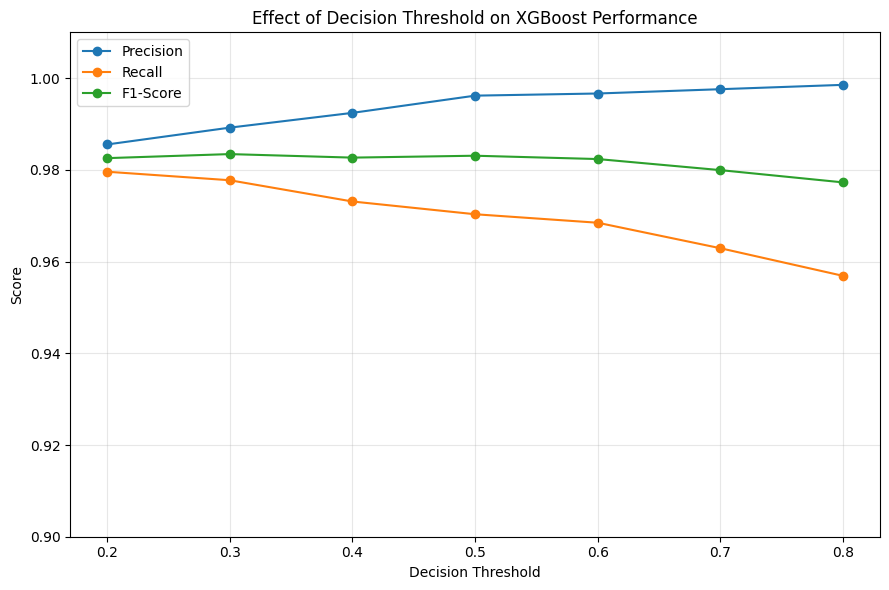

In [ ]:
# ==========================================
# Threshold Performance Plot
# ==========================================

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Effect of Decision Threshold on XGBoost Performance")

plt.ylim(0.90, 1.01)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Final JobShield Prototype Validation
# ==========================================

validation_jobs = {

    "Obvious Scam": """
    Immediate hiring. Earn 5000 per week working from home.
    No experience or degree required. Flexible hours.
    Contact us now and start earning immediately.
    """,

    "Professional Software Role": """
    We are seeking an experienced software engineer to join our
    development team. The successful candidate will design,
    develop and maintain software applications and collaborate
    with cross-functional teams. Applicants should have
    experience with Python and software engineering principles.
    """,

    "Suspicious Data Entry Role": """
    Data entry workers required immediately. Work from home
    with flexible hours and earn excellent weekly income.
    No previous experience required. Contact our hiring team
    today for immediate consideration.
    """,

    "Professional Analyst Role": """
    We are recruiting a data analyst to support our analytics
    team. Responsibilities include analysing business data,
    developing reports and communicating findings to
    stakeholders. Candidates should have experience with SQL,
    Python and data visualisation.
    """
}

validation_results = []

for name, text in validation_jobs.items():

    cleaned = clean_text(text)
    vector = tfidf_clean.transform([cleaned])

    probability = xgb_clean.predict_proba(vector)[0, 1]
    prediction = int(probability >= 0.30)

    validation_results.append({
        "Test Case": name,
        "Fraud Probability": probability,
        "Prediction":
            "Fraudulent" if prediction == 1 else "Legitimate"
    })

validation_results = pd.DataFrame(validation_results)

validation_results["Fraud Probability"] = (
    validation_results["Fraud Probability"] * 100
).round(2)

display(validation_results)

,Test Case,Fraud Probability,Prediction
0,Obvious Scam,99.970001,Fraudulent
1,Professional Software Role,2.100000,Legitimate
2,Suspicious Data Entry Role,99.980003,Fraudulent
3,Professional Analyst Role,5.570000,Legitimate
